# 07 · XGBoost (gradient-boosted trees)

The boosted ensemble: shallow-to-medium trees fitted sequentially to the residuals of the previous ones (`xgboost.XGBClassifier`, histogram method). It is the second high-capacity ensemble next to Random Forest. `scale_pos_weight=1` is the XGBoost equivalent of `class_weight=None`.

**Protocol (identical for every model; `src/controlled_framework.py`, `config.yaml`):**
- **Novelty-aware tuning.** Optuna TPE, the same number of trials for every model. The objective is the mean ROC-AUC over 5 *leave-attack-types-out* folds of `KDDTrain+`: each fold holds out a group of training attack types plus 1/5 of the normal rows, so the score measures how well held-out attack types are separated from normal traffic. The preprocessor is refit inside every fold.
- **Fixed parameters.** `class_weight=None` (or its equivalent) for every model; `random_state` = the run's seed.
- **Final refit.** On all of `KDDTrain+` with the **full** best-trial parameter set (tuned + fixed); `cf.check_final_params` asserts it.
- **Single evaluation on `KDDTest+`**, reported four ways:
  - at the fixed threshold 0.5;
  - threshold-free (ROC-AUC, PR-AUC, AUC of seen attacks vs normals, AUC of unseen attacks vs normals);
  - at FPR budgets of 1/2/5% read off the test ROC curve (ranking quality at a matched FPR);
  - at *deployable* thresholds, chosen so that 1/2/5% of the out-of-fold `KDDTrain+` normals exceed them. These use training data only, so the realised test FPR can differ from the budget.
- **Seeds.** The whole pipeline (tuning + refit + evaluation) runs once per seed in `config.yaml`. The primary seed (42) writes the model and the headline files; the other seeds write to `results/*/seeds/`.

**Outputs:** `models/xgboost.joblib`, `results/metrics/xgboost.json`, `results/predictions/xgboost_predictions.csv`, `results/predictions/xgboost_oof_train_scores.csv`, `results/tuning/xgboost_trials.{json,csv}`, `results/*/seeds/xgboost_seed*.*`, `results/tables/xgboost_*.{csv,md}`, `results/figures/xgboost/*.png`.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


## 1. Search space and fixed parameters

In [2]:
MODEL_NAME = "XGBoost"
FIXED = {"objective": "binary:logistic", "tree_method": "hist", "eval_metric": "logloss",
         "scale_pos_weight": 1.0, "n_jobs": -1, "random_state": cf.SEED}
FOLD_JOBS = 1   # CV folds run in parallel for single-threaded estimators

def suggest(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

from xgboost import XGBClassifier

def factory(params):
    return XGBClassifier(**params)

def complexity(pipe, preds):
    clf = pipe.named_steps["clf"]
    tdf = clf.get_booster().trees_to_dataframe()
    leaves = tdf[tdf["Feature"] == "Leaf"].groupby("Tree").size()
    return {"n_trees": int(tdf["Tree"].nunique()), "max_depth": int(clf.max_depth),
            "mean_leaves": float(leaves.mean()), "total_leaves": int(leaves.sum())}

print("fixed:", FIXED)

fixed: {'objective': 'binary:logistic', 'tree_method': 'hist', 'eval_metric': 'logloss', 'scale_pos_weight': 1.0, 'n_jobs': -1, 'random_state': 42}


## 2. Primary seed: tune (novelty CV), refit on `KDDTrain+`, evaluate once on `KDDTest+`

In [3]:
data = cf.load_dataset()
res = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=cf.SEED, data=data, fold_jobs=FOLD_JOBS)
res.metrics["model_complexity"] = complexity(res.pipeline, res.predictions)
print()
print("best novelty CV AUC:", round(res.best_cv_auc, 4), "| fold AUCs:", np.round(res.best_cv_fold_aucs, 4))
print("final model parameters:", res.best_params)
print("model complexity:", res.metrics["model_complexity"])

  [XGBoost | seed 42] trial 01/25  novelty CV AUC 0.9722 (±0.0401)
  [XGBoost | seed 42] trial 02/25  novelty CV AUC 0.9437 (±0.0775)
  [XGBoost | seed 42] trial 03/25  novelty CV AUC 0.9646 (±0.0328)
  [XGBoost | seed 42] trial 04/25  novelty CV AUC 0.9611 (±0.0430)
  [XGBoost | seed 42] trial 05/25  novelty CV AUC 0.9746 (±0.0195)
  [XGBoost | seed 42] trial 06/25  novelty CV AUC 0.9682 (±0.0306)
  [XGBoost | seed 42] trial 07/25  novelty CV AUC 0.9813 (±0.0225)
  [XGBoost | seed 42] trial 08/25  novelty CV AUC 0.9699 (±0.0369)
  [XGBoost | seed 42] trial 09/25  novelty CV AUC 0.9650 (±0.0270)
  [XGBoost | seed 42] trial 10/25  novelty CV AUC 0.9650 (±0.0358)
  [XGBoost | seed 42] trial 11/25  novelty CV AUC 0.9686 (±0.0375)
  [XGBoost | seed 42] trial 12/25  novelty CV AUC 0.9610 (±0.0535)
  [XGBoost | seed 42] trial 13/25  novelty CV AUC 0.9499 (±0.0647)
  [XGBoost | seed 42] trial 14/25  novelty CV AUC 0.9623 (±0.0562)
  [XGBoost | seed 42] trial 15/25  novelty CV AUC 0.9707 (±0.0

## 3. Tuning results

The cell also reports how far apart the best trials are relative to the fold-to-fold standard deviation. A spread smaller than one fold SD means this objective does not clearly separate the top configurations.

top-5 spread = 0.00278  vs  best-trial fold SD = 0.01642


,trial,mean_auc,std_auc,duration_seconds,objective,tree_method,eval_metric,scale_pos_weight,n_jobs,random_state,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda
0,20,0.982192,0.016415,8.49,binary:logistic,hist,logloss,1.0,-1,42,150,5,0.021269,14.468107,0.710883,0.763833,0.981743
1,6,0.981266,0.022518,8.89,binary:logistic,hist,logloss,1.0,-1,42,100,7,0.040307,7.277151,0.724684,0.760034,0.153759
2,22,0.980683,0.019493,10.47,binary:logistic,hist,logloss,1.0,-1,42,200,6,0.033423,8.269628,0.688384,0.867850,9.747081
3,18,0.980088,0.022154,10.10,binary:logistic,hist,logloss,1.0,-1,42,200,6,0.022953,9.043295,0.678133,0.806034,3.081763
4,21,0.979417,0.020052,11.68,binary:logistic,hist,logloss,1.0,-1,42,200,4,0.020500,15.007473,0.721537,0.750899,1.344690
5,23,0.978838,0.023699,11.42,binary:logistic,hist,logloss,1.0,-1,42,200,5,0.031676,5.670794,0.728646,0.776297,8.821341
6,17,0.978690,0.022838,10.77,binary:logistic,hist,logloss,1.0,-1,42,150,5,0.028888,4.471730,0.641529,0.833698,3.026603
7,4,0.974584,0.019508,7.20,binary:logistic,hist,logloss,1.0,-1,42,200,2,0.103647,1.666698,0.626021,0.974443,7.286654
8,0,0.972184,0.040054,12.57,binary:logistic,hist,logloss,1.0,-1,42,150,7,0.145185,6.009975,0.662407,0.577997,0.001707
9,15,0.971648,0.037887,6.88,binary:logistic,hist,logloss,1.0,-1,42,100,6,0.059106,9.770810,0.736572,0.791719,0.163619


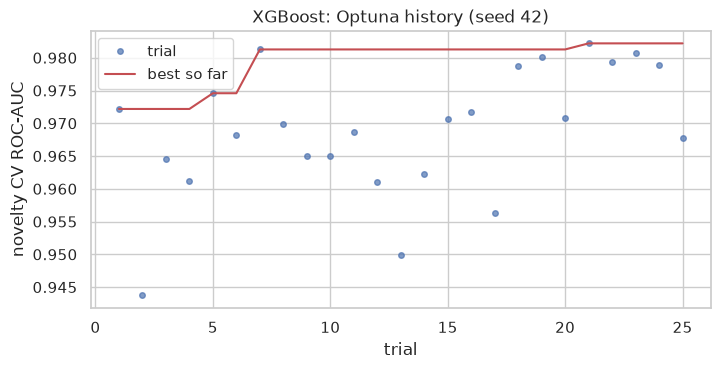

In [4]:
tt = cf.trials_table(res)
spread = tt["mean_auc"].iloc[0] - tt["mean_auc"].iloc[min(4, len(tt) - 1)]
print(f"top-5 spread = {spread:.5f}  vs  best-trial fold SD = {np.std(res.best_cv_fold_aucs):.5f}")
display(tt.head(10))

fig, ax = plt.subplots(figsize=(8, 3.6))
vals = [t["mean_auc"] for t in res.trials]
ax.plot(range(1, len(vals) + 1), vals, "o", ms=4, alpha=.7, label="trial")
ax.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), "-", color="#C44E52", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("novelty CV ROC-AUC"); ax.set_title(f"{MODEL_NAME}: Optuna history (seed {cf.SEED})"); ax.legend()
cf.save_figure(fig, "xgboost", "tuning_history"); plt.show()

## 4. Test results (`KDDTest+`)

In [5]:
m = res.metrics
display(pd.Series(cf.summary_row(m)).to_frame(MODEL_NAME))
ops = pd.concat({"test ROC reading (matched test FPR)": pd.DataFrame(m["test_roc_operating_points"]).T,
                 "deployable (OOF-calibrated threshold)": pd.DataFrame(m["deployable_operating_points"]).T}).reset_index(names=["kind", "budget"])
cat = pd.DataFrame(m["attack_category_recall"]).T.reset_index(names="category")
strat = pd.DataFrame([{"category": c, "seen_n": v["seen"]["total_samples"], "seen_recall": v["seen"]["recall"],
                       "unseen_n": v["unseen"]["total_samples"], "unseen_recall": v["unseen"]["recall"]}
                      for c, v in m["category_stratified_seen_unseen_recall"].items()])
unseen = pd.DataFrame(m["per_unseen_attack_recall"]).T.reset_index(names="attack").sort_values("total_samples", ascending=False)
cf.save_table(ops, "xgboost_operating_points")
cf.save_table(cat, "xgboost_category_recall")
cf.save_table(strat, "xgboost_category_stratified")
cf.save_table(unseen, "xgboost_per_unseen_attack")
display(ops); display(strat); display(unseen)

,XGBoost
model,XGBoost
accuracy,0.781884
macro_f1,0.781162
attack_precision,0.970295
attack_recall,0.636328
false_positive_rate,0.025747
seen_recall,0.7821
unseen_recall,0.2832
generalization_drop_pp,49.89
reweighted_drop_pp,54.69


,kind,budget,threshold,fpr,attack_recall,seen_recall,unseen_recall
0,test ROC reading (matched test FPR),fpr_1pct,0.974082,0.009681,0.450090,0.614665,0.051467
1,test ROC reading (matched test FPR),fpr_2pct,0.949952,0.019979,0.526689,0.711329,0.079467
2,test ROC reading (matched test FPR),fpr_5pct,0.078945,0.049949,0.849295,0.860729,0.821600
3,deployable (OOF-calibrated threshold),fpr_1pct,0.186414,0.032853,0.776202,0.848838,0.600267
4,deployable (OOF-calibrated threshold),fpr_2pct,0.106249,0.045211,0.819060,0.855334,0.731200
5,deployable (OOF-calibrated threshold),fpr_5pct,0.052057,0.105355,0.859113,0.864142,0.846933


,category,seen_n,seen_recall,unseen_n,unseen_recall
0,DoS,5741,0.9979,1717,0.0909
1,Probe,1106,0.9991,1315,0.6662
2,R2L,2199,0.1219,688,0.0378
3,U2R,37,0.0541,30,0.1333


,attack,category,total_samples,detected,missed,recall
3,mscan,Probe,996,564,432,0.5663
0,apache2,DoS,737,0,737,0.0
5,processtable,DoS,685,154,531,0.2248
10,snmpguess,R2L,331,0,331,0.0
7,saint,Probe,319,312,7,0.9781
2,mailbomb,DoS,293,0,293,0.0
9,snmpgetattack,R2L,178,0,178,0.0
1,httptunnel,R2L,133,22,111,0.1654
4,named,R2L,17,4,13,0.2353
6,ps,U2R,15,2,13,0.1333


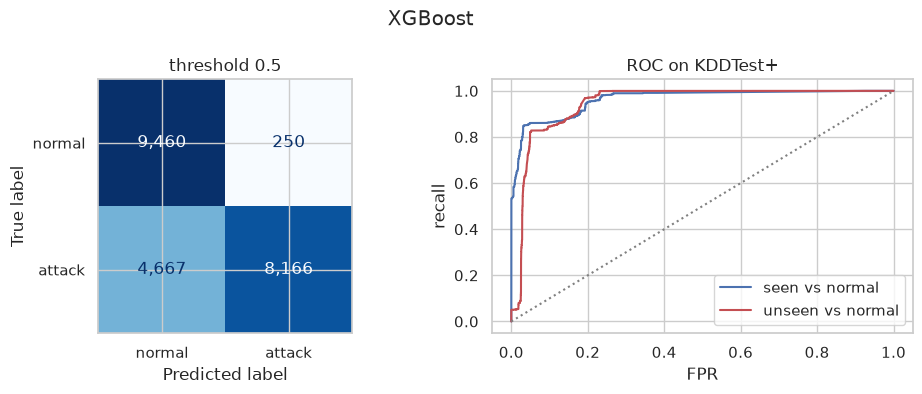

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(np.array(m["overall_metrics"]["confusion_matrix"]), display_labels=["normal", "attack"]).plot(
    ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("threshold 0.5")
p = res.predictions
for name, mask, col in [("seen vs normal", (p.y_true == 0) | ~p.is_unseen, "#4C72B0"), ("unseen vs normal", (p.y_true == 0) | p.is_unseen, "#C44E52")]:
    fpr, tpr, _ = roc_curve(p.y_true[mask], p.y_prob[mask]); axes[1].plot(fpr, tpr, color=col, label=name)
axes[1].plot([0, 1], [0, 1], ":", color="grey"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("recall"); axes[1].legend()
axes[1].set_title("ROC on KDDTest+")
fig.suptitle(MODEL_NAME); fig.tight_layout()
cf.save_figure(fig, "xgboost", "confusion_and_roc"); plt.show()

## 5. Save primary-seed artifacts

In [7]:
paths = cf.save_experiment(res, primary=True)
for k, v in paths.items():
    print(f"{k:12s} {v.relative_to(PROJECT_ROOT)}")

metrics      results/metrics/xgboost.json
predictions  results/predictions/xgboost_predictions.csv
tuning_json  results/tuning/xgboost_trials.json
tuning_csv   results/tuning/xgboost_trials.csv
model        models/xgboost.joblib
oof          results/predictions/xgboost_oof_train_scores.csv


## 6. Remaining seeds (full pipeline per seed)

In [8]:
seed_rows = [cf.summary_row(res.metrics) | {"seed": cf.SEED, "best_novelty_cv_auc": res.best_cv_auc}]
for s in [s for s in cf.SEEDS if s != cf.SEED]:
    r = cf.run_controlled_experiment(MODEL_NAME, suggest, factory, FIXED, seed=s, data=data, fold_jobs=FOLD_JOBS, verbose=False)
    r.metrics["model_complexity"] = complexity(r.pipeline, r.predictions)
    cf.save_experiment(r, primary=False)
    seed_rows.append(cf.summary_row(r.metrics) | {"seed": s, "best_novelty_cv_auc": r.best_cv_auc})
    print(f"seed {s}: CV AUC {r.best_cv_auc:.4f} | test unseen AUC {r.metrics['threshold_free']['roc_auc_unseen_vs_normal']:.4f} | "
          f"unseen recall@0.5 {r.metrics['seen_vs_unseen_recall']['unseen_recall']:.4f} | params { {k: v for k, v in r.best_params.items() if k not in FIXED} }")
    del r
seeds_tbl = pd.DataFrame(seed_rows)
cols = ["seed", "best_novelty_cv_auc", "macro_f1", "false_positive_rate", "seen_recall", "unseen_recall",
        "auc_seen_vs_normal", "auc_unseen_vs_normal", "unseen_recall@test_fpr_2pct", "test_fpr@oof_fpr_2pct", "unseen_recall@oof_fpr_2pct"]
seeds_tbl = seeds_tbl[cols]
cf.save_table(seeds_tbl, "xgboost_seeds")
display(seeds_tbl)
display(seeds_tbl.drop(columns="seed").agg(["mean", "std"]).T)

seed 1: CV AUC 0.9882 | test unseen AUC 0.9429 | unseen recall@0.5 0.2811 | params {'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.02612445980514219, 'min_child_weight': 7.746017270450647, 'subsample': 0.9687620563954409, 'colsample_bytree': 0.7091840385474458, 'reg_lambda': 0.34003901882475224}
seed 2: CV AUC 0.9861 | test unseen AUC 0.9427 | unseen recall@0.5 0.3736 | params {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.020148904038582688, 'min_child_weight': 11.009010772159487, 'subsample': 0.7606504149460691, 'colsample_bytree': 0.7728053908674244, 'reg_lambda': 0.0011121889265056758}
seed 3: CV AUC 0.9875 | test unseen AUC 0.9357 | unseen recall@0.5 0.2877 | params {'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.020642447745845633, 'min_child_weight': 3.272028861930123, 'subsample': 0.8377958431253922, 'colsample_bytree': 0.7318395282752045, 'reg_lambda': 0.5163087760348771}
seed 4: CV AUC 0.9825 | test unseen AUC 0.9479 | unseen recall@0.5 0.3923 | pa

,seed,best_novelty_cv_auc,macro_f1,false_positive_rate,seen_recall,unseen_recall,auc_seen_vs_normal,auc_unseen_vs_normal,unseen_recall@test_fpr_2pct,test_fpr@oof_fpr_2pct,unseen_recall@oof_fpr_2pct
0,42,0.982192,0.781162,0.025747,0.7821,0.2832,0.962921,0.946587,0.079467,0.045211,0.731200
1,1,0.988212,0.782656,0.027394,0.7883,0.2811,0.970422,0.942915,0.078667,0.093100,0.811467
2,2,0.986100,0.796495,0.027703,0.7840,0.3736,0.968061,0.942690,0.053600,0.080844,0.710133
3,3,0.987531,0.778933,0.028115,0.7773,0.2877,0.964700,0.935668,0.078667,0.092276,0.799467
4,4,0.982485,0.796629,0.027600,0.7765,0.3923,0.975678,0.947940,0.053867,0.043254,0.824533


,mean,std
best_novelty_cv_auc,0.985304,0.002814
macro_f1,0.787175,0.008671
false_positive_rate,0.027312,0.000913
seen_recall,0.781640,0.004883
unseen_recall,0.323580,0.054651
auc_seen_vs_normal,0.968356,0.005022
auc_unseen_vs_normal,0.943160,0.004770
unseen_recall@test_fpr_2pct,0.068853,0.013807
test_fpr@oof_fpr_2pct,0.070937,0.024864
unseen_recall@oof_fpr_2pct,0.775360,0.051253


**Reading these numbers.** Seed-to-seed spread shows how much of any difference between models comes from training and tuning randomness rather than from the model family. The cross-model comparison is in `08_evaluation_comparison.ipynb`.